<p style="color:#FFF; background:#224D2E; padding:12px; font-size:20px; font-style:italic; text-align:center">
<span style="width:49%; display:inline-block; text-align:left">Projet 2025</span>
<span style="width:49%; display:inline-block; text-align:right">OUTINFO</span>
<span style="font-size:40px; font-style:normal"><b>LA POLLUTION DE L'AIR</b></span><br>
<span style="width:49%; display:inline-block; text-align:left">Ndeye Penda Diatta</span>
<span style="width:49%; display:inline-block; text-align:right">Léo Gautreau</p>

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import requests as rq
from datetime import date, timedelta
import warnings; warnings.filterwarnings('ignore') # suppression des 'warning' de l'interpréteur
from SRC.tools import show, inspect, cutcut # import des fonctions utilitaires du module 'tools'
import time
import plotly.express as px # import du package 'plotly.express' avec alias 'px'
import plotly.graph_objects as go
import ipywidgets as ws # import du package 'ipywidgets' (indispensable pour utiliser 'ipyleaflet')
import ipyleaflet as lf # import du package 'ipyleaflet' avec alias habituel 'lf'
from scipy.stats import pearsonr

<h2 style="padding:16px; color:#FFF; background:#3B824E">A - FETCH, CLEAN, STRUCTURE</h2>

<h3 style="padding:16px; color:#FFF; background:#4DAB66">1 - Données de pollution</h3>

Les mesures des polluants ont été récupérés manuellement depuis https://object.infra.data.gouv.fr/browser/ineris-prod/lcsqa%2Fconcentrations-de-polluants-atmospheriques-reglementes%2Ftemps-reel%2F. Elles reprennent les concentrations de divers polluants (O3, NO, NO2, ...) sur l'année 2024 pour l'ensemble des stations météorologiques de France. Elles sont conservées dans le dossier *data pollution* et classées par mois.
<br><br>
Nous les avons toutes regroupées dans un même dataframe *data* avec le code ci-dessous.

In [7]:
base_dir = Path("data pollution/2024")
mois = ["Janvier", "Février", "Mars", "Avril", "Mai", "Juin", "Juillet", "Août", "Septembre", "Octobre", "Novembre", "Décembre"]

dfs = []

for m in mois:
    mois_dir = base_dir/m
    fichiers = sorted(mois_dir.glob("*.csv"))
    for file in fichiers:
        df = pd.read_csv(file, sep=';', low_memory=False)

        df["année"] = 2024
        df["mois"] = m

        df["date"] = pd.to_datetime(file.stem.split("_")[-1])
        dfs.append(df)

data = pd.concat(dfs, ignore_index=True)

print("Nombre total de lignes :", len(data))
print("Colonnes :", list(data.columns))

data.head()

Nombre total de lignes : 18386802
Colonnes : ['Date de début', 'Date de fin', 'Organisme', 'code zas', 'Zas', 'code site', 'nom site', "type d'implantation", 'Polluant', "type d'influence", 'discriminant', 'Réglementaire', "type d'évaluation", 'procédure de mesure', 'type de valeur', 'valeur', 'valeur brute', 'unité de mesure', 'taux de saisie', 'couverture temporelle', 'couverture de données', 'code qualité', 'validité', 'année', 'mois', 'date']


,Date de début,Date de fin,Organisme,code zas,Zas,code site,nom site,type d'implantation,Polluant,type d'influence,...,valeur brute,unité de mesure,taux de saisie,couverture temporelle,couverture de données,code qualité,validité,année,mois,date
0,2024/01/01 00:00:00,2024/01/01 01:00:00,ATMO GRAND EST,FR44ZAG02,ZAG METZ,FR01011,Metz-Centre,Urbaine,NO,Fond,...,NaN,µg-m3,NaN,NaN,NaN,N,-1,2024,Janvier,2024-01-01
1,2024/01/01 01:00:00,2024/01/01 02:00:00,ATMO GRAND EST,FR44ZAG02,ZAG METZ,FR01011,Metz-Centre,Urbaine,NO,Fond,...,NaN,µg-m3,NaN,NaN,NaN,N,-1,2024,Janvier,2024-01-01
2,2024/01/01 02:00:00,2024/01/01 03:00:00,ATMO GRAND EST,FR44ZAG02,ZAG METZ,FR01011,Metz-Centre,Urbaine,NO,Fond,...,NaN,µg-m3,NaN,NaN,NaN,N,-1,2024,Janvier,2024-01-01
3,2024/01/01 03:00:00,2024/01/01 04:00:00,ATMO GRAND EST,FR44ZAG02,ZAG METZ,FR01011,Metz-Centre,Urbaine,NO,Fond,...,NaN,µg-m3,NaN,NaN,NaN,N,-1,2024,Janvier,2024-01-01
4,2024/01/01 04:00:00,2024/01/01 05:00:00,ATMO GRAND EST,FR44ZAG02,ZAG METZ,FR01011,Metz-Centre,Urbaine,NO,Fond,...,NaN,µg-m3,NaN,NaN,NaN,N,-1,2024,Janvier,2024-01-01


Pour nettoyer *data*, on supprime les lignes qui ne contiennent aucune valeur dans la colonne **valeur** et on enlève aussi les polluants qui ne nous intéressent pas.

In [8]:
data = data.dropna(subset=["valeur"])
data = data[(data["Polluant"] != "NOX as NO2") & (data["Polluant"] != "SO2") &
  (data["Polluant"] != "CO") & (data["Polluant"] != "C6H6" )]

data.head()

,Date de début,Date de fin,Organisme,code zas,Zas,code site,nom site,type d'implantation,Polluant,type d'influence,...,valeur brute,unité de mesure,taux de saisie,couverture temporelle,couverture de données,code qualité,validité,année,mois,date
48,2024/01/01 00:00:00,2024/01/01 01:00:00,ATMO GRAND EST,FR44ZAG02,ZAG METZ,FR01011,Metz-Centre,Urbaine,O3,Fond,...,63.425,µg-m3,NaN,NaN,NaN,R,1,2024,Janvier,2024-01-01
50,2024/01/01 02:00:00,2024/01/01 03:00:00,ATMO GRAND EST,FR44ZAG02,ZAG METZ,FR01011,Metz-Centre,Urbaine,O3,Fond,...,66.075,µg-m3,NaN,NaN,NaN,R,1,2024,Janvier,2024-01-01
51,2024/01/01 03:00:00,2024/01/01 04:00:00,ATMO GRAND EST,FR44ZAG02,ZAG METZ,FR01011,Metz-Centre,Urbaine,O3,Fond,...,65.300,µg-m3,NaN,NaN,NaN,R,1,2024,Janvier,2024-01-01
52,2024/01/01 04:00:00,2024/01/01 05:00:00,ATMO GRAND EST,FR44ZAG02,ZAG METZ,FR01011,Metz-Centre,Urbaine,O3,Fond,...,66.100,µg-m3,NaN,NaN,NaN,R,1,2024,Janvier,2024-01-01
53,2024/01/01 05:00:00,2024/01/01 06:00:00,ATMO GRAND EST,FR44ZAG02,ZAG METZ,FR01011,Metz-Centre,Urbaine,O3,Fond,...,67.775,µg-m3,NaN,NaN,NaN,R,1,2024,Janvier,2024-01-01


<h3 style="padding:16px; color:#FFF; background:#4DAB66">2 - Données météorologiques</h3>

Récupérons les 250 stations qui ont récolté le plus de données sur l'année 2024

In [9]:
top250_stations = data.groupby('nom site')['valeur'].count().sort_values(ascending=False).head(250).index
data_top250 = data[data['nom site'].isin(top250_stations)]

Sur le site https://www.geodair.fr/donnees/referentiel-mesure, nous avons téléchargé toutes les informations nécessaires sur toutes les stations de France. Nous récupérons le fichier `.csv` pour ne garder que le nom, la latitude et la longitude des stations

In [10]:
stations = pd.read_csv("Localisations_stations.csv", sep=';', low_memory=False)

stations = stations[['Latitude', 'Longitude', 'Nom']]
stations_top250 = stations[stations['Nom'].isin(top250_stations)]

En reprenant le code fourni dans le chapitre 10-Extraction, nous récupérons les relevés horaires de température moyenne, d'humidité et de vitesse moyenne du vent pour les 250 stations sur toute l'année 2024.

In [8]:
def url_post(url, **args):
  """apply POST request on provided URL, using optional arguments stored as arbitrary keyword arguments"""
  headers = {'User-Agent':'Mozilla/5.0', 'x-api-key':'reqres-free-v1'} # use Mozilla/Firefox user agent
  data = rq.post(url, headers=headers, data=args) # connect to provided URL and try to get data
  data.raise_for_status() # raise HTTPError exception when connection or server error
  return data.json() # return data in JSON format when status is OK

url = 'https://archive-api.open-meteo.com/v1/archive'  # API archives météo
queries = 'temperature_2m relative_humidity_2m windspeed_10m'.split()  # données à récupérer

all_dfs = []

for index, row in stations_top250.iterrows():
    lat = row['Latitude']
    lon = row['Longitude']
    nom = row['Nom']

    json = url_post(
        url,
        latitude=lat,
        longitude=lon,
        start_date="2024-01-01",
        end_date="2024-12-31",
        hourly=queries,
        timezone="Europe/Paris"
    )

    df = pd.DataFrame({
        "datetime": json['hourly']['time'],
        "temperature": json['hourly']['temperature_2m'],
        "humidity": json['hourly']['relative_humidity_2m'],
        "windspeed": json['hourly']['windspeed_10m']
    })

    df['nom_site'] = nom
    df['latitude'] = lat
    df['longitude'] = lon

    all_dfs.append(df)

    time.sleep(0.5)


Transposons cette `liste` en un `dataframe` et changeons le format de la date et de l'heure pour de meilleures interprétations.

In [11]:
meteo_2024_top250 = pd.concat(all_dfs, ignore_index=True)
meteo_2024_top250['datetime'] = pd.to_datetime(meteo_2024_top250['datetime'])

NameError: name 'all_dfs' is not defined

Mettons toutes ces données dans un fichier `csv` pour ne pas avoir à relancer l'API à chaque fois.

In [12]:
meteo_2024_top250.to_csv("meteo2024.csv",index=False)

NameError: name 'meteo_2024_top250' is not defined

Ne relancer que cette ligne dans cette sous-partie :

In [3]:
meteo2024 = pd.read_csv("meteo2024.csv", parse_dates=["datetime"])
meteo2024

,datetime,temperature,humidity,windspeed,nom_site,latitude,longitude
0,2024-01-01 00:00:00,6.4,80,26.0,Metz-Centre,49.119442,6.180833
1,2024-01-01 01:00:00,6.0,83,25.2,Metz-Centre,49.119442,6.180833
2,2024-01-01 02:00:00,6.2,86,26.0,Metz-Centre,49.119442,6.180833
3,2024-01-01 03:00:00,6.2,86,26.0,Metz-Centre,49.119442,6.180833
4,2024-01-01 04:00:00,5.7,89,28.2,Metz-Centre,49.119442,6.180833
...,...,...,...,...,...,...,...
2090587,2024-12-31 19:00:00,-2.3,93,5.7,Baume-les-Dames,47.351288,6.359722
2090588,2024-12-31 20:00:00,-2.0,93,8.6,Baume-les-Dames,47.351288,6.359722
2090589,2024-12-31 21:00:00,-1.3,89,9.6,Baume-les-Dames,47.351288,6.359722
2090590,2024-12-31 22:00:00,-2.0,88,6.2,Baume-les-Dames,47.351288,6.359722


<h3 style="padding:16px; color:#FFF; background:#4DAB66">3 - Données finales</h3>

Préparons le jeu de données finales réunissant les données de pollution et météorologiques dans un même dataframe pour pouvoir travailler plus simplement et directement dessus.

In [14]:
# Harmonisation des formats de la date
data_top250 = data_top250.rename(columns={"Date de début": "datetime"})
data_top250["datetime"] = pd.to_datetime(data_top250["datetime"])

In [15]:
# Besoin de pivoter la colonne polluant pour créer une colonne par polluant dans le nouveau df
polluants_pivot = data_top250.pivot_table(index=["nom site", "datetime"],
                                          columns="Polluant",
                                          values="valeur").reset_index()
polluants_pivot.columns.name = None

In [16]:
# Coller les relevés horaires météos aux relevés horaires des polluants pour toutes les stations avec leurs coordonnées.
df_final = (
    meteo2024.merge(
        data_top250[data_top250["Polluant"].isin(["O3","NO","NO2","PM10","PM2.5"])]
        .pivot_table(index=["nom site","datetime"], columns="Polluant", values="valeur")
        .reset_index()
        .merge(data_top250[["nom site","type d'implantation"]].drop_duplicates(), on="nom site", how="left"),
        how="left",
        left_on=["nom_site","datetime"],
        right_on=["nom site","datetime"]
    )
    .drop(columns=["nom site"])
)


In [ ]:
# Conversion en .csv pour pouvoir retravailler dessus
df_final
df_final.to_csv("Projet.csv",index=False)

Ne relancer que cette ligne dans cette sous-partie :

In [2]:
projet = pd.read_csv("Projet.csv")

<h2 style="padding:16px; color:#FFF; background:#3B824E">B - MODEL, ANALYZE, VISUALIZE</h2>
<h3 style="padding:16px; color:#FFF; background:#4DAB66">1 - La concentration des polluants et le type d'implantation</h3>

Les causes probables des polluants atmosphériques sont le trafic routier ou l'activité industrielle, surtout présents aux alentours et dans les villes. Nous chercherons donc à mettre en lien les concentrations moyennes mensuelles des polluants avec le type d'implantation des stations. <br>
<br>
Pour se donner un ordre d'idée, on pourrait déjà regarder la moyenne annuelle de 2024 en fonction du type d'implantation.

In [5]:
projet.groupby("type d'implantation")[["O3", "NO", "NO2", "PM10", "PM2.5"]].mean()

,O3,NO,NO2,PM10,PM2.5
type d'implantation,,,,,
Périurbaine,50.881478,4.947217,9.830664,14.901333,7.895136
Rurale nationale,57.844032,0.328108,2.073134,8.629077,5.219096
Rurale près des villes,51.633127,1.075399,4.589029,11.335731,7.532343
Rurale régionale,50.410614,0.736662,3.558163,10.352805,7.260929
Urbaine,49.852834,6.146570,13.142360,14.113449,8.116231


En moyenne, la concentration de polluants semble être plus élevée quand on s'approche des villes sauf pour l'ozone. Cela peut sûrement s'expliquer par le fait que le rejet des autres polluants est surtout dû au trafic routier, surtout présent dans les villes et aux alentours. Calculons le rapport de corrélation $ \eta^2 $ pour s'en assurer.

In [11]:
moyennes_annuelles = (projet.groupby(["nom_site", "type d'implantation"])[["O3", "NO", "NO2", "PM10", "PM2.5"]].mean().reset_index())
moyennes_annuelles

,nom_site,type d'implantation,O3,NO,NO2,PM10,PM2.5
0,A7 SUD LYONNAIS,Périurbaine,NaN,26.741119,30.477691,22.324459,11.030273
1,A7 Salaise Ouest,Périurbaine,NaN,21.810876,29.705292,16.547435,9.548761
2,AIRVAULT - Stade Laillé,Périurbaine,52.500337,0.709684,5.049543,12.619031,NaN
3,AIX CENTRE ECOLE ART,Urbaine,NaN,5.411899,14.109497,14.328862,7.549018
4,AJACCIO CANETTO,Urbaine,54.226430,4.846163,12.614284,18.842815,9.125374
...,...,...,...,...,...,...,...
218,Villefranche Centre,Urbaine,39.572684,5.025452,16.142554,13.332712,9.013405
219,Voiron Urbain,Urbaine,47.048570,3.150132,10.827114,9.552986,NaN
220,Zone Rurale SE,Rurale régionale,48.843714,0.227802,4.172320,NaN,5.563390
221,Zoodyssée Chizé,Rurale régionale,50.668291,0.382260,1.394391,10.784639,6.359425


In [7]:
# Effectifs intra-groupes
eff_zone = moyennes_annuelles.groupby("type d'implantation")[["O3", "NO", "NO2", "PM10", "PM2.5"]].count()
# Variances intra-groupes
var_zone = moyennes_annuelles.groupby("type d'implantation")[["O3", "NO", "NO2", "PM10", "PM2.5"]].var()
# Effectifs totaux
eff_poll = eff_zone.sum()
# Variances totales
var_poll = moyennes_annuelles[["O3", "NO", "NO2", "PM10", "PM2.5"]].var()

# A partir de ces dfs et de ces listes on peut construire une fonction qui nous renverra tous les rapports de corrélations souhaités :
def rapp_corr(z, poll):

  for zone in z:
    num = 0
    num += eff_zone.loc[zone, poll] * var_zone.loc[zone, poll]

  denom = eff_poll[poll] * var_poll[poll]
  eta_carre = 1 - (num / denom)

  print(f"Le rapport de corrélation (η²) entre le type d'implantation et {poll} est {eta_carre:.3f}")


In [8]:
zones = moyennes_annuelles["type d'implantation"].unique().tolist()
polluants = ["O3", "NO", "NO2", "PM10", "PM2.5"]

for polluant in polluants:
  rapp_corr(zones, polluant)

Le rapport de corrélation (η²) entre le type d'implantation et O3 est 0.998
Le rapport de corrélation (η²) entre le type d'implantation et NO est 1.000
Le rapport de corrélation (η²) entre le type d'implantation et NO2 est 0.998
Le rapport de corrélation (η²) entre le type d'implantation et PM10 est 0.971
Le rapport de corrélation (η²) entre le type d'implantation et PM2.5 est 0.974


Les rapports de corrélations sont extrêment proches de 1 et donc nous devrions pouvoir expliquer toute la variabilité des polluants par le type d'implantation. Seulement, il est extrêmement important de nuancer ce propos car nous utilisons des moyennes annuelles et il y a de fortes disparités intra-groupes. Ces résultats se doivent d'être complétés au moins par des boxplots parallèles.

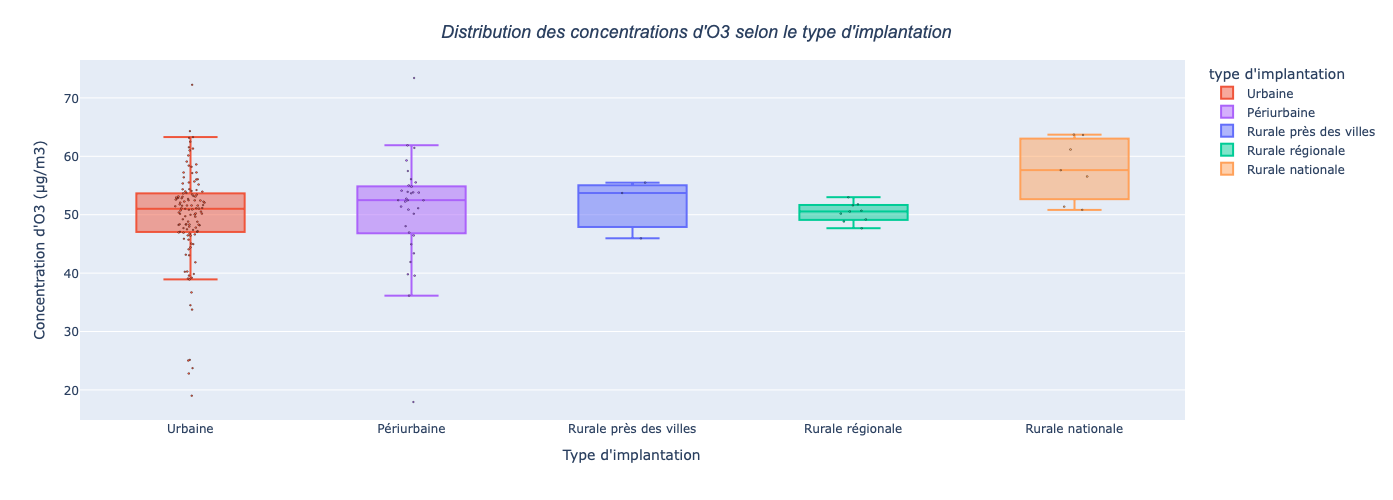

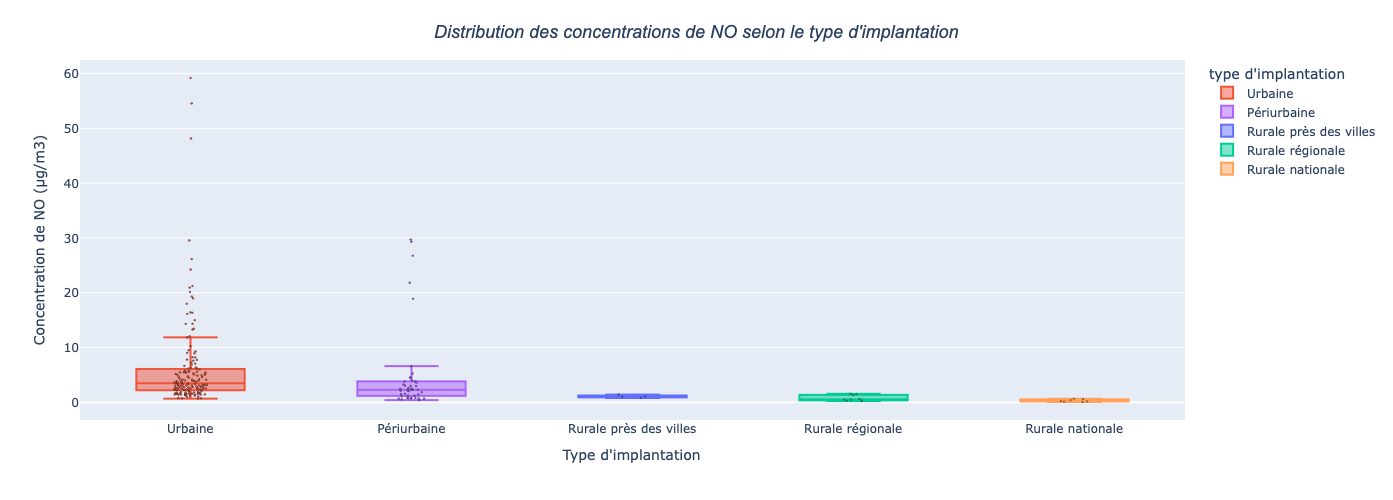

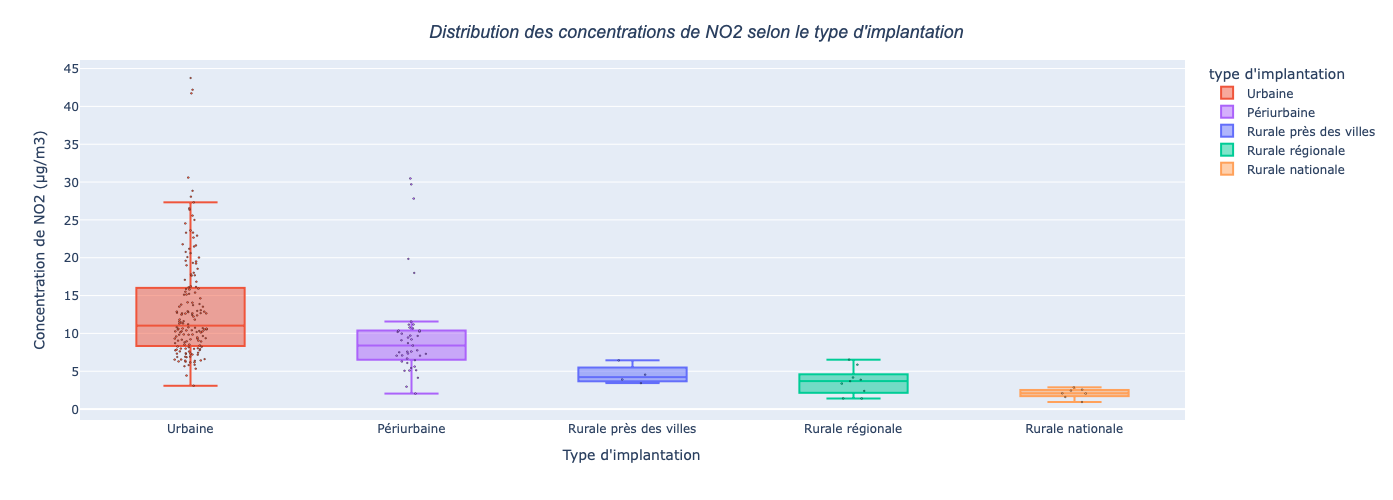

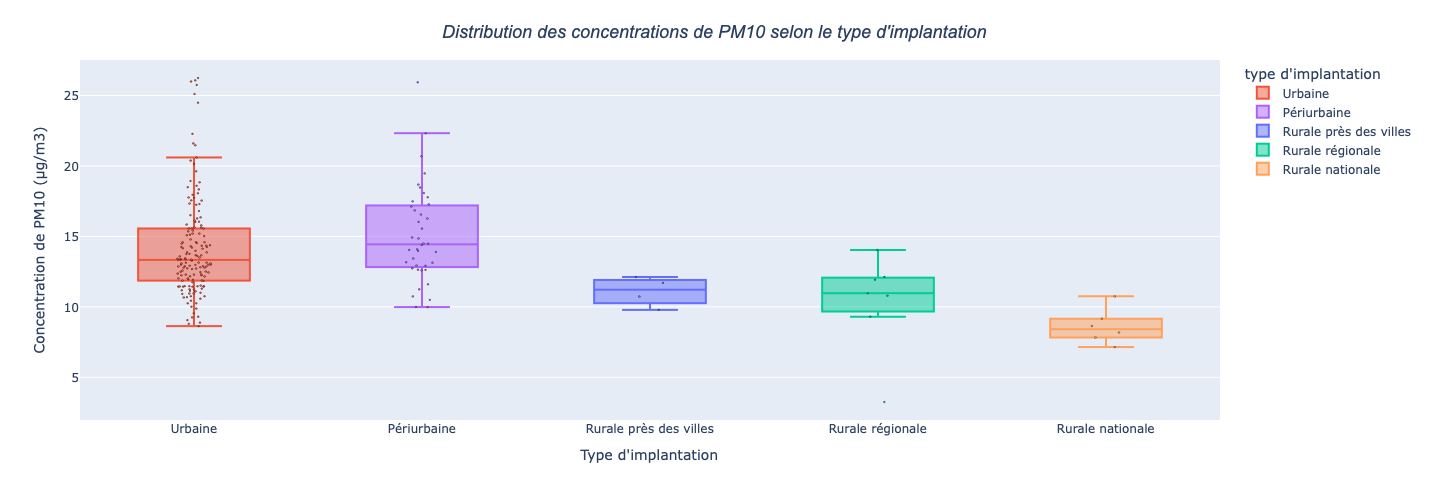

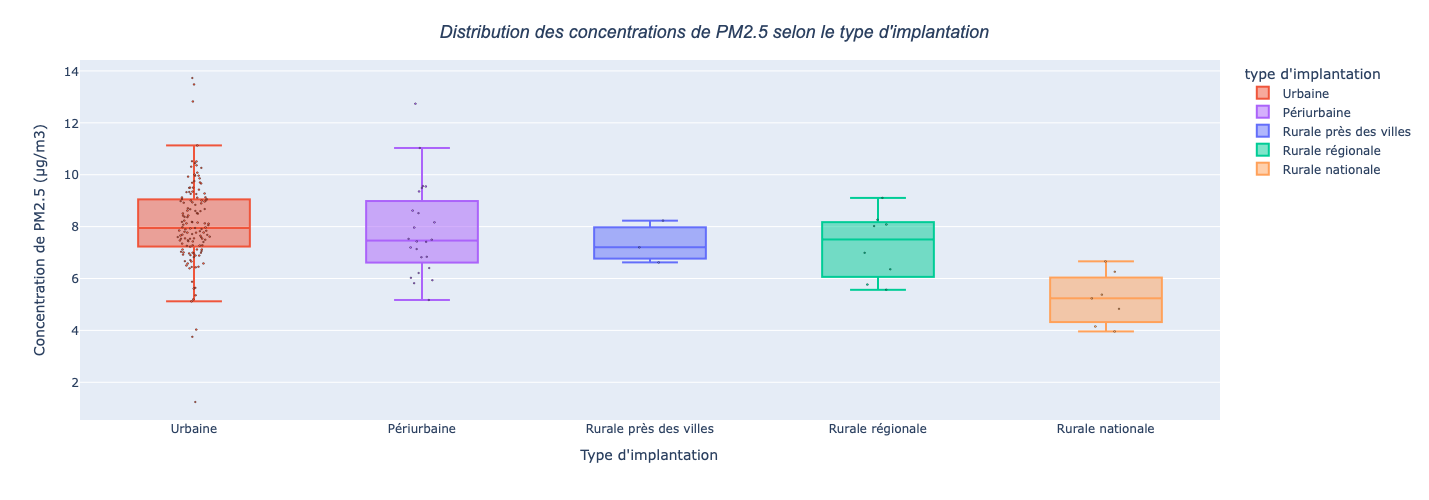

In [9]:
# Style
ordre_zones = ["Urbaine", "Périurbaine", "Rurale près des villes", "Rurale régionale", "Rurale nationale"] # en fonction de l'éloignement des villes
palette_default = px.colors.qualitative.Plotly
color_mapping = {
    "Urbaine": palette_default[1],
    "Périurbaine": palette_default[3],
    "Rurale près des villes": palette_default[0],
    "Rurale régionale": palette_default[2],
    "Rurale nationale": palette_default[4]
}

# Boxplots parallèles
## O3
fig1 = px.box(moyennes_annuelles, x="type d'implantation", y="O3", points="all",color="type d'implantation", hover_data=["nom_site"],
             category_orders={"type d'implantation": ordre_zones}, color_discrete_map=color_mapping)
fig1.update_traces(jitter=False, pointpos=0, marker=dict(opacity=1, size=2), marker_line_color="black", marker_line_width=0.3)
fig1.update_layout(height=500, xaxis_title="Type d'implantation", yaxis_title="Concentration d'O3 (µg/m3)",
                  title=dict(text="Distribution des concentrations d'O3 selon le type d'implantation", x=0.5,y=0.95,
                             font=dict(size=18, family="Arial", style="italic")))
fig1.show()

## NO
fig2 = px.box(moyennes_annuelles, x="type d'implantation", y="NO", points="all",color="type d'implantation", hover_data=["nom_site"],
             category_orders={"type d'implantation": ordre_zones}, color_discrete_map=color_mapping)
fig2.update_traces(jitter=False, pointpos=0, marker=dict(opacity=1, size=2), marker_line_color="black", marker_line_width=0.3)
fig2.update_layout(height=500, xaxis_title="Type d'implantation", yaxis_title="Concentration de NO (µg/m3)",
                  title=dict(text="Distribution des concentrations de NO selon le type d'implantation", x=0.5,y=0.95,
                             font=dict(size=18, family="Arial", style="italic")))
fig2.show()

## NO2
fig3 = px.box(moyennes_annuelles, x="type d'implantation", y="NO2", points="all",color="type d'implantation", hover_data=["nom_site"],
             category_orders={"type d'implantation": ordre_zones}, color_discrete_map=color_mapping)
fig3.update_traces(jitter=False, pointpos=0, marker=dict(opacity=1, size=2), marker_line_color="black", marker_line_width=0.3)
fig3.update_layout(height=500, xaxis_title="Type d'implantation", yaxis_title="Concentration de NO2 (µg/m3)",
                  title=dict(text="Distribution des concentrations de NO2 selon le type d'implantation", x=0.5,y=0.95,
                             font=dict(size=18, family="Arial", style="italic")))
fig3.show()

## PM10
fig4 = px.box(moyennes_annuelles, x="type d'implantation", y="PM10", points="all",color="type d'implantation", hover_data=["nom_site"],
             category_orders={"type d'implantation": ordre_zones}, color_discrete_map=color_mapping)
fig4.update_traces(jitter=False, pointpos=0, marker=dict(opacity=1, size=2), marker_line_color="black", marker_line_width=0.3)
fig4.update_layout(height=500, xaxis_title="Type d'implantation", yaxis_title="Concentration de PM10 (µg/m3)",
                  title=dict(text="Distribution des concentrations de PM10 selon le type d'implantation", x=0.5,y=0.95,
                             font=dict(size=18, family="Arial", style="italic")))
fig4.show()

## PM2.5
fig5 = px.box(moyennes_annuelles, x="type d'implantation", y="PM2.5", points="all",color="type d'implantation", hover_data=["nom_site"],
             category_orders={"type d'implantation": ordre_zones}, color_discrete_map=color_mapping)
fig5.update_traces(jitter=False, pointpos=0, marker=dict(opacity=1, size=2), marker_line_color="black", marker_line_width=0.3)
fig5.update_layout(height=500, xaxis_title="Type d'implantation", yaxis_title="Concentration de PM2.5 (µg/m3)",
                  title=dict(text="Distribution des concentrations de PM2.5 selon le type d'implantation", x=0.5,y=0.95,
                             font=dict(size=18, family="Arial", style="italic")))
fig5.show()

Les boxplots parallèles semblent confirmer l'hypothèse d'une corrélation des concentrations des polluants atmosphériques avec la proximité des villes pour les NO, NO2, PM10 et PM2.5. Ceci pourrait parfaitement être expliqué par la très forte présence de voiture aux alentours des villes. D'autant plus que pour les zones urbaines et périurbaines, les boxplots mettent aussi en évidence des points extrêmes. En s'y intéressant de plus près, on remarque que ces stations sont directement placées aux abords de voies rapides, appuyant notre hypothèse. <br>
Néanmoins, en ce qui concerne l'O3, les boxplots ne semblent pas révélés un aspect assez significatif pour établir une corrélation entre sa concentration et le type d'implantation. Le rejet d'ozone demande donc de se pencher sur de nouveaux facteurs tels que des données météorologiques.

<h3 style="padding:16px; color:#FFF; background:#4DAB66">2 - La concentration d'O3 et les données météorologiques</h3>

Tout d'abord, on peut facilement supposer que les données météorologiques récoltées (température, humidité, vitesse du vent) sont liées au moment de leur relève (il fait plus chaud l'après-midi ou en été). On peut alors créer des sous-jeux de données correspondants aux moyennes horaires des données météorologiques et des concentrations en O3.

In [26]:
# Récupérer l'heure dans une colonne
projet["datetime"] = pd.to_datetime(projet["datetime"], errors="coerce")
projet["heure"] = projet["datetime"].dt.hour

# Création df
moyennes_horaires = projet.groupby(["heure"])[["O3", "temperature", "humidity", "windspeed"]].mean().reset_index()
moyennes_horaires

,heure,O3,temperature,humidity,windspeed
0,0,43.268377,11.750155,85.327584,10.914111
1,1,42.308262,11.459551,86.147700,10.837497
2,2,41.407601,11.394920,86.789253,10.898620
3,3,40.006383,11.169225,87.360246,10.857952
4,4,38.068619,10.995730,87.756318,10.818293
5,5,36.379540,10.874288,87.998645,10.816580
6,6,36.842829,10.910281,87.932650,10.887526
7,7,40.789836,11.306982,86.843317,11.081315
8,8,47.074077,12.039336,84.515221,11.307911
9,9,53.411269,13.030307,81.144547,11.785631


En moyenne, il semblerait que plus la température ou la vitesse du vent est élevée, plus la concentration horaire en ozone est forte et inversement avec l'humidité. Pour appuyer notre hypothèse, nous pouvons calculer la corrélation entre ces variables.

In [33]:
corr_T = moyennes_horaires["O3"].corr(moyennes_horaires["temperature"])
corr_H = moyennes_horaires["O3"].corr(moyennes_horaires["humidity"])
corr_V = moyennes_horaires["O3"].corr(moyennes_horaires["windspeed"])
print(f"corr(température, concentration O3) = {corr_T:.3f}")
print(f"corr(humidité, concentration O3) = {corr_H:.3f}")
print(f"corr(vitesse du vent, concentration O3) = {corr_V:.3f}")

corr(température, concentration O3) = 0.957
corr(humidité, concentration O3) = -0.956
corr(vitesse du vent, concentration O3) = 0.962


Ces statistiques bivariées justifient encore nos hypothèses. D'ailleurs, on remarque pour l'humidité que la corrélation est négative, donc nous nous concentrerons sur le déficit d'humidité par la suite. <br>
<br>
Visualisons la concentration moyenne horaire de l'ozone sous forme de diagramme en barres :

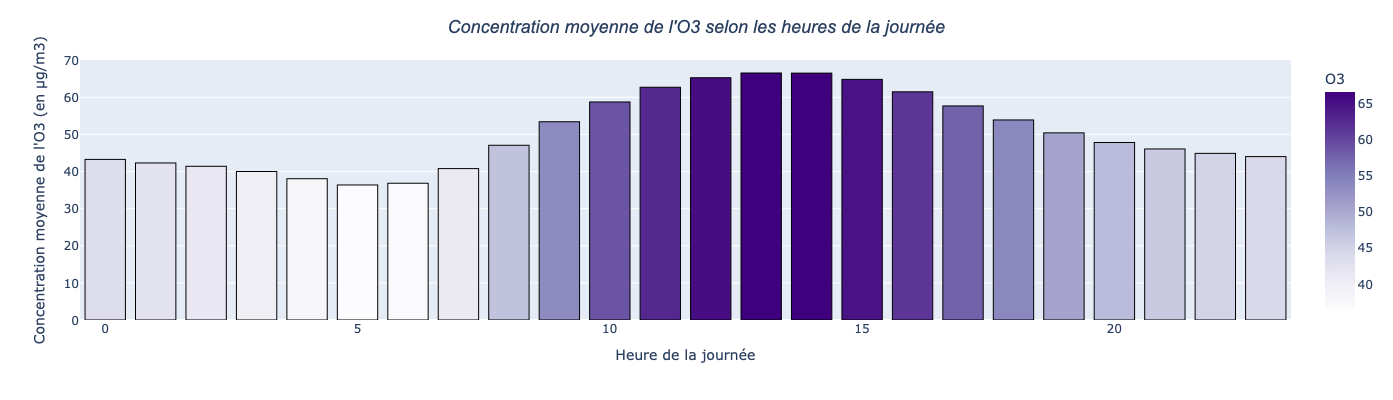

In [46]:
fig = px.bar(moyennes_horaires, x="heure", y="O3", color = "O3", color_continuous_scale="Purples")
fig.update_traces(marker_line_color='black', marker_line_width=1) # paramètres graphiques des marqueurs
fig.update_layout(height=400, xaxis_title="Heure de la journée", yaxis_title="Concentration moyenne de l'O3 (en µg/m3)",
  legend=dict(x=.8, y=.95), title=dict(text="Concentration moyenne de l'O3 selon les heures de la journée",
  font=dict(size=18, family='Arial', style='italic'), x=0.5, y=0.95)) # paramètres graphiques de la figure
fig.show()

Il apparaît effectivement que la concentration est plus forte l'après-midi alors superposons les courbes de variations horaires des températures moyennes, vitesse moyenne du vent et déficit moyen d'humidité pour une meilleure visualisation :

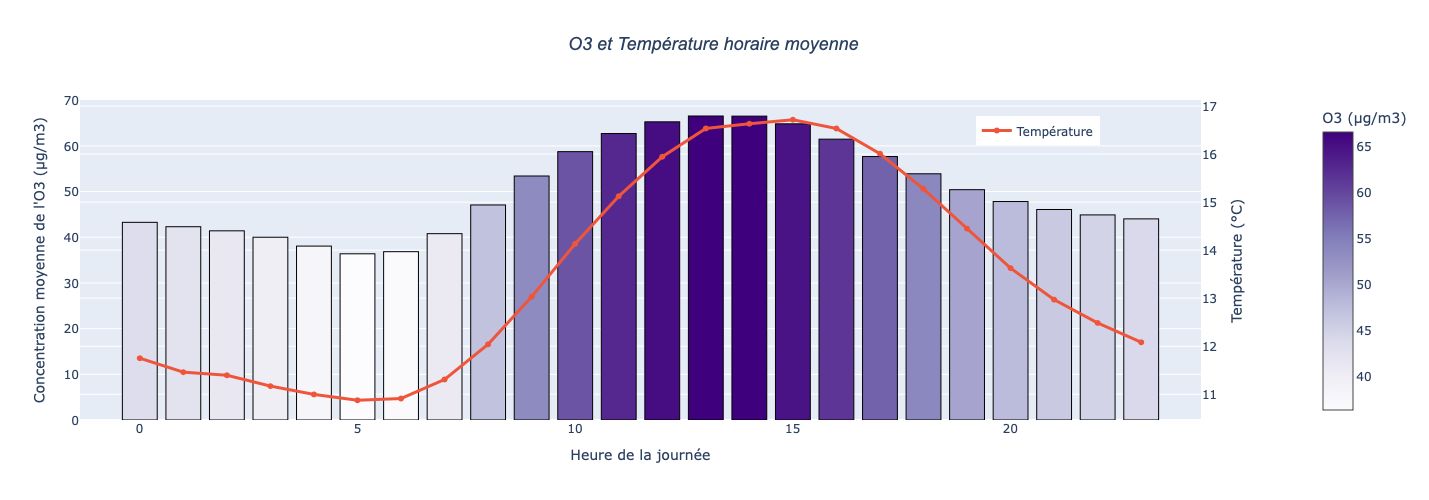

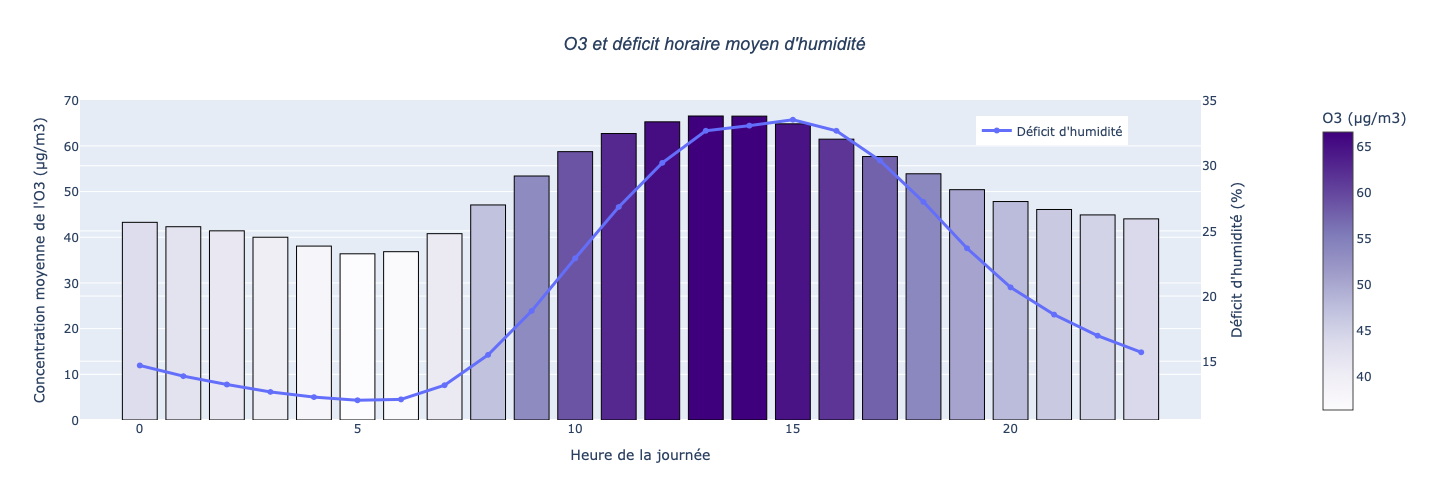

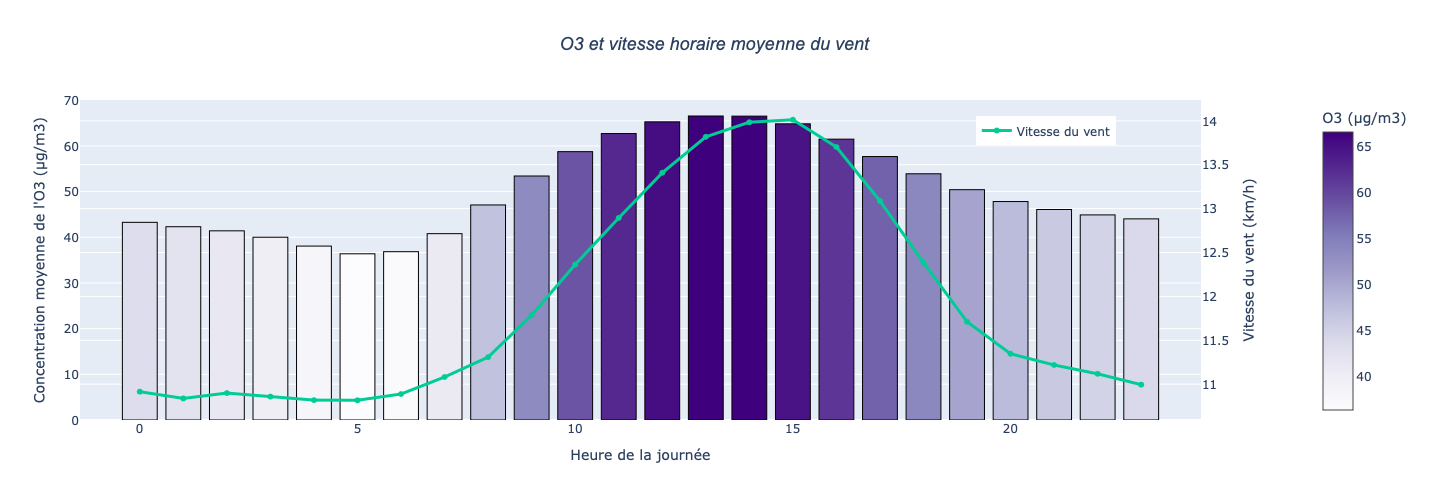

In [79]:
figT = go.Figure()

# Pour garder l'intensité des couleurs du barplot de l'O3
colorscale = px.colors.sequential.Purples
o3_norm = (moyennes_horaires["O3"] - moyennes_horaires["O3"].min()) / \
          (moyennes_horaires["O3"].max() - moyennes_horaires["O3"].min())
color_indices = (o3_norm * (len(colorscale)-1)).round().astype(int)
bar_colors = [colorscale[i] for i in color_indices]

# Barplot O3
figT.add_trace(go.Bar(x=moyennes_horaires["heure"], y=moyennes_horaires["O3"], name="O3",
                      showlegend = False,
                      marker=dict(
            color=moyennes_horaires["O3"],  # valeurs qui pilotent le dégradé
            colorscale="Purples",
            line=dict(color='black', width=1),
            colorbar=dict(title="O3 (µg/m3)", x=1.1)  # légende du gradient
        ), yaxis="y1"))

# Température
figT.add_trace(go.Scatter(x=moyennes_horaires["heure"], y=moyennes_horaires["temperature"], name="Température",
                                 mode="lines+markers", line=dict(color=palette_default[1], width=3), yaxis="y2"))

# Axes
figT.update_layout(title=dict(text="O3 et Température horaire moyenne", x=0.5,
                                     font=dict(size=18, family='Arial', style='italic')),
                          xaxis=dict(title="Heure de la journée"),
                          yaxis=dict(title="Concentration moyenne de l'O3 (µg/m3)", side="left"),
                          yaxis2=dict(title="Température (°C)", overlaying="y", side="right"),
                          height=500, legend=dict(x=.8, y=.95))

figT.show()


# Déficit d'humidité
figH = go.Figure()

figH.add_trace(go.Bar(
    x=moyennes_horaires["heure"],
    y=moyennes_horaires["O3"],
    showlegend=False,
    marker=dict(
        color=moyennes_horaires["O3"],
        colorscale="Purples",
        line=dict(color="black", width=1),
        colorbar=dict(title="O3 (µg/m3)", x=1.1)
    ),
    yaxis="y1"
))

figH.add_trace(go.Scatter(
    x=moyennes_horaires["heure"],
    y=100 - moyennes_horaires["humidity"],
    name="Déficit d'humidité",
    mode="lines+markers",
    line=dict(color=palette_default[0], width=3),
    yaxis="y2"
))

figH.update_layout(
    title=dict(text="O3 et déficit horaire moyen d'humidité", x=0.5,
               font=dict(size=18, family="Arial", style="italic")),
    xaxis=dict(title="Heure de la journée"),
    yaxis=dict(title="Concentration moyenne de l'O3 (µg/m3)", side="left"),
    yaxis2=dict(title="Déficit d'humidité (%)", overlaying="y", side="right"),
    height=500,
    legend=dict(x=.8, y=.95)
)

figH.show()


# Vent

figV = go.Figure()

figV.add_trace(go.Bar(
    x=moyennes_horaires["heure"],
    y=moyennes_horaires["O3"],
    showlegend=False,
    marker=dict(
        color=moyennes_horaires["O3"],
        colorscale="Purples",
        line=dict(color="black", width=1),
        colorbar=dict(title="O3 (µg/m3)", x=1.1)
    ),
    yaxis="y1"
))

figV.add_trace(go.Scatter(
    x=moyennes_horaires["heure"],
    y=moyennes_horaires["windspeed"],
    name="Vitesse du vent",
    mode="lines+markers",
    line=dict(color=palette_default[2], width=3),
    yaxis="y2"
))

figV.update_layout(
    title=dict(text="O3 et vitesse horaire moyenne du vent", x=0.5,
               font=dict(size=18, family="Arial", style="italic")),
    xaxis=dict(title="Heure de la journée"),
    yaxis=dict(title="Concentration moyenne de l'O3 (µg/m3)", side="left"),
    yaxis2=dict(title="Vitesse du vent (km/h)", overlaying="y", side="right"),
    height=500,
    legend=dict(x=.8, y=.95)
)

figV.show()


Enfin, il est clair que les courbes suivent la même tendance que la concentration horaire moyenne d'O3 et ces figures viennent appuyer encore un peu plus nos hypothèses. Toutefois, il ne faut pas négliger l’impact des autres données météorologiques. En effet, celles-ci sont souvent corrélées les unes des autres et ce travail apporte donc une piste de réflexion supplémentaire quant à l’influence de celles-ci sur les moyennes horaires de la température et du déficit d’humidité.